# Notebook 03: Modelos de regresión lineal, interpretación y conclusiones
**Proyecto final: emisiones de CO₂ per cápita (Our World in Data)** · Responsables: Ana (modelos) y todo el grupo (interpretación)

Este notebook usa los datos limpios del notebook 01 (`../data/co2_limpio_2019.csv`).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

AZUL = "#2a6fbb"      # color principal de datos
GRIS = "#8a8f98"      # contexto / comparaciones
ROJO = "#c8452f"      # resaltar un caso o la recta del modelo
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10,
})

ANIO = 2019   # mismo año de análisis que el notebook 01

limpio = pd.read_csv("../data/co2_limpio_2019.csv")    # salida del notebook 01
print(f"Países en el modelo: {limpio.shape[0]} (año {ANIO})")

Países en el modelo: 164 (año 2019)


---
# Parte 3. Modelos de regresión lineal
*Responsable: Ana*

Se ajustan tres modelos, de menor a mayor complejidad, y se comparan:

| Modelo | Ecuación | Idea |
|---|---|---|
| 1. Simple | CO₂ pc = b₀ + b₁·Energía pc | ¿Solo la energía explica las emisiones? |
| 2. Múltiple | CO₂ pc = b₀ + b₁·Energía pc + b₂·PIB pc | ¿El ingreso aporta algo más? |
| 3. Log-log | ln(CO₂ pc) = b₀ + b₁·ln(Energía pc) + b₂·ln(PIB pc) | Corrige el sesgo y la dispersión creciente |

## 3.1 Preparación: partición entrenamiento / prueba

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

y = limpio["co2_per_capita"]
X = limpio[["energy_per_capita", "gdp_per_capita"]]

# 80 % para entrenar y 20 % para evaluar con datos que el modelo no vio
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Entrenamiento: {len(X_tr)} países | Prueba: {len(X_te)} países")

resultados = {}
def evaluar(nombre, y_real, y_pred):
    # Métricas siempre en toneladas por persona, para poder comparar los tres modelos
    y_real, y_pred = np.asarray(y_real), np.asarray(y_pred)
    resultados[nombre] = {
        "R² (prueba)": r2_score(y_real, y_pred),
        "RMSE (t/persona)": np.sqrt(mean_squared_error(y_real, y_pred)),
        "MAE (t/persona)": mean_absolute_error(y_real, y_pred),
        "Error relativo mediano (%)": np.median(np.abs(y_pred / y_real - 1)) * 100,
    }

Entrenamiento: 131 países | Prueba: 33 países


## 3.2 Modelo 1: regresión lineal simple

In [3]:
m1 = LinearRegression().fit(X_tr[["energy_per_capita"]], y_tr)
pred1 = m1.predict(X_te[["energy_per_capita"]])
evaluar("1. Simple (energía)", y_te, pred1)

b0, b1 = m1.intercept_, m1.coef_[0]
print(f"CO₂ pc = {b0:.3f} + {b1:.6f} · Energía pc")
print(f"Por cada 1 000 kWh adicionales por persona, el CO₂ per cápita sube {b1*1000:.3f} t")
print(f"R² entrenamiento = {m1.score(X_tr[['energy_per_capita']], y_tr):.3f} | R² prueba = {r2_score(y_te, pred1):.3f}")

CO₂ pc = 0.832 + 0.000148 · Energía pc
Por cada 1 000 kWh adicionales por persona, el CO₂ per cápita sube 0.148 t
R² entrenamiento = 0.785 | R² prueba = 0.594


C:\Users\ANA\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


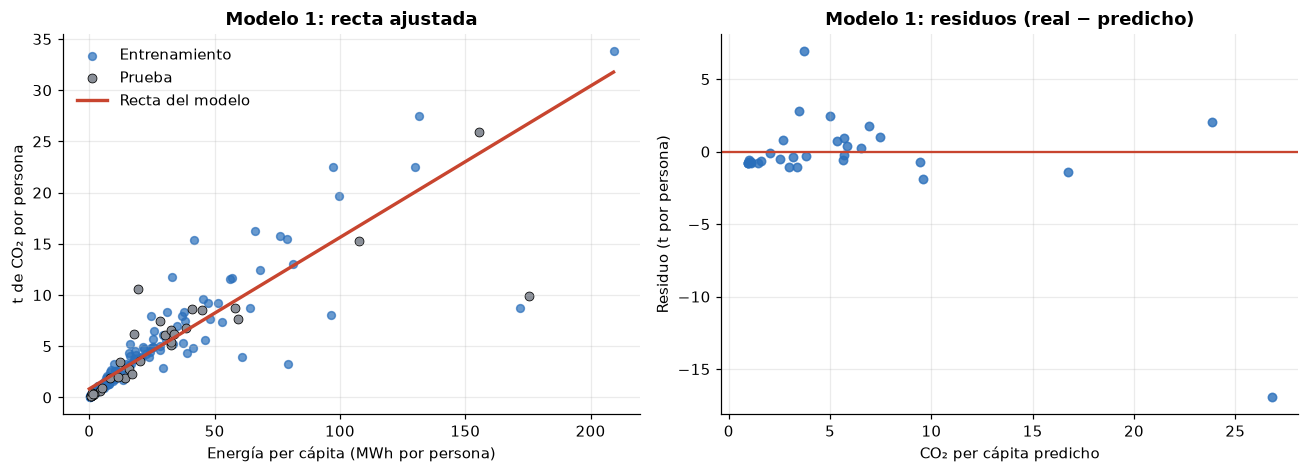

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

xs = np.linspace(0, limpio["energy_per_capita"].max(), 100).reshape(-1, 1)
axes[0].scatter(X_tr["energy_per_capita"] / 1000, y_tr, s=26, color=AZUL, alpha=0.7, label="Entrenamiento")
axes[0].scatter(X_te["energy_per_capita"] / 1000, y_te, s=34, color=GRIS, edgecolor="black", lw=0.5, label="Prueba")
axes[0].plot(xs / 1000, m1.predict(xs), color=ROJO, lw=2.2, label="Recta del modelo")
axes[0].set_title("Modelo 1: recta ajustada")
axes[0].set_xlabel("Energía per cápita (MWh por persona)"); axes[0].set_ylabel("t de CO₂ por persona")
axes[0].legend(frameon=False)

resid = y_te - pred1
axes[1].scatter(pred1, resid, s=30, color=AZUL, alpha=0.8)
axes[1].axhline(0, color=ROJO, lw=1.5)
axes[1].set_title("Modelo 1: residuos (real − predicho)")
axes[1].set_xlabel("CO₂ per cápita predicho"); axes[1].set_ylabel("Residuo (t por persona)")
plt.tight_layout(); plt.show()

**Diagnóstico:** la recta sigue bien la tendencia de la gran mayoría de países (los de consumo bajo y medio). Los errores grandes aparecen en la zona alta: en el gráfico de residuos hay un caso extremo con un residuo cercano a −17 t por persona. Más abajo se identifica ese país y se mide cuánto pesa en las métricas.

## 3.3 Modelo 2: regresión lineal múltiple (energía + PIB)

In [5]:
m2 = LinearRegression().fit(X_tr, y_tr)
pred2 = m2.predict(X_te)
evaluar("2. Múltiple (energía + PIB)", y_te, pred2)

print(f"CO₂ pc = {m2.intercept_:.3f} + {m2.coef_[0]:.6f}·Energía pc + {m2.coef_[1]:.6f}·PIB pc")
print(f"Efecto de +1 000 kWh de energía pc (PIB constante): {m2.coef_[0]*1000:+.3f} t")
print(f"Efecto de +10 000 USD de PIB pc (energía constante): {m2.coef_[1]*10000:+.3f} t")
print(f"R² prueba = {r2_score(y_te, pred2):.3f}")

CO₂ pc = 0.884 + 0.000154·Energía pc + -0.000010·PIB pc
Efecto de +1 000 kWh de energía pc (PIB constante): +0.154 t
Efecto de +10 000 USD de PIB pc (energía constante): -0.105 t
R² prueba = 0.573


## 3.4 Modelo 3: regresión log-log

In [6]:
# Transformación logarítmica: las variables quedan en escala relativa (porcentajes)
Xl = np.log(X)
yl = np.log(y)
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(Xl, yl, test_size=0.2, random_state=42)

m3 = LinearRegression().fit(Xl_tr, yl_tr)
predl = m3.predict(Xl_te)

# Para comparar con los otros modelos se regresa a toneladas por persona
pred3 = np.exp(predl)
y_te3 = np.exp(yl_te)
evaluar("3. Log-log (energía + PIB)", y_te3, pred3)

print(f"ln(CO₂ pc) = {m3.intercept_:.3f} + {m3.coef_[0]:.3f}·ln(Energía pc) + {m3.coef_[1]:.3f}·ln(PIB pc)")
print(f"Elasticidad de la energía: un +10 % de energía pc se asocia con {((1.10**m3.coef_[0])-1)*100:+.1f} % de CO₂ pc")
print(f"Elasticidad del PIB:       un +10 % de PIB pc se asocia con {((1.10**m3.coef_[1])-1)*100:+.1f} % de CO₂ pc")
print(f"R² prueba (escala logarítmica) = {r2_score(yl_te, predl):.3f}")

ln(CO₂ pc) = -7.389 + 0.998·ln(Energía pc) + -0.118·ln(PIB pc)
Elasticidad de la energía: un +10 % de energía pc se asocia con +10.0 % de CO₂ pc
Elasticidad del PIB:       un +10 % de PIB pc se asocia con -1.1 % de CO₂ pc
R² prueba (escala logarítmica) = 0.947


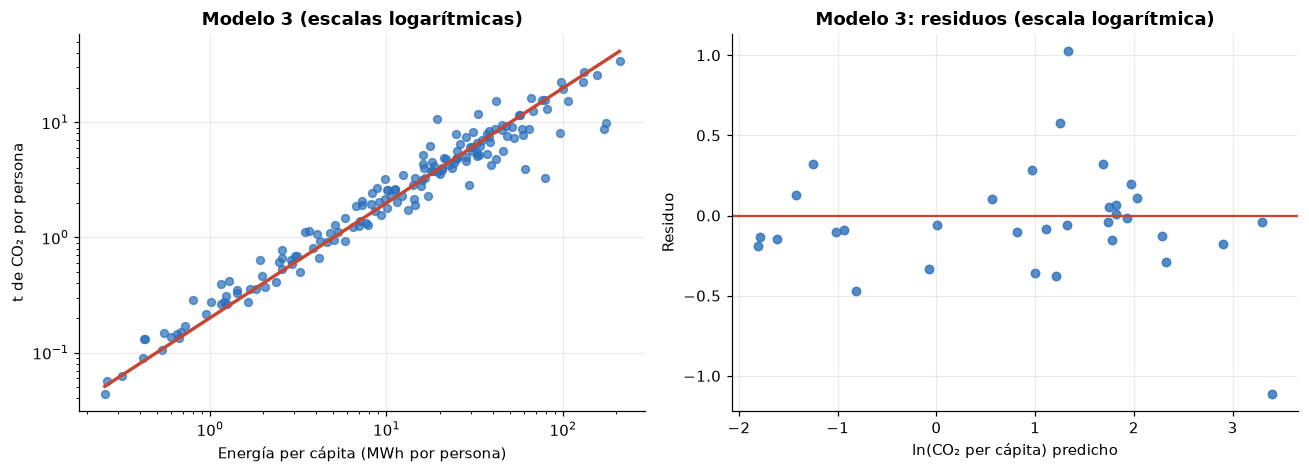

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

axes[0].scatter(np.exp(Xl["energy_per_capita"]) / 1000, y, s=26, color=AZUL, alpha=0.7)
orden = np.argsort(Xl["energy_per_capita"].values)
# Recta del modelo 3 fijando el PIB en su mediana, solo para visualizar la relación con la energía
x_e = np.linspace(Xl["energy_per_capita"].min(), Xl["energy_per_capita"].max(), 100)
y_hat = m3.intercept_ + m3.coef_[0] * x_e + m3.coef_[1] * Xl["gdp_per_capita"].median()
axes[0].plot(np.exp(x_e) / 1000, np.exp(y_hat), color=ROJO, lw=2.2)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_title("Modelo 3 (escalas logarítmicas)")
axes[0].set_xlabel("Energía per cápita (MWh por persona)"); axes[0].set_ylabel("t de CO₂ por persona")

resid3 = yl_te - predl
axes[1].scatter(predl, resid3, s=30, color=AZUL, alpha=0.8)
axes[1].axhline(0, color=ROJO, lw=1.5)
axes[1].set_title("Modelo 3: residuos (escala logarítmica)")
axes[1].set_xlabel("ln(CO₂ per cápita) predicho"); axes[1].set_ylabel("Residuo")
plt.tight_layout(); plt.show()

En escala logarítmica la relación se ve claramente lineal y los residuos quedan repartidos de forma pareja alrededor de cero, sin tendencia evidente. El único punto claramente alejado es el mismo caso extremo del modelo 1.

## 3.5 Comparación de los modelo

In [8]:
tabla = pd.DataFrame(resultados).T
print("Métricas en TONELADAS POR PERSONA (escala original), conjunto de prueba:")
tabla


Métricas en TONELADAS POR PERSONA (escala original), conjunto de prueba:


,R² (prueba),RMSE (t/persona),MAE (t/persona),Error relativo mediano (%)
1. Simple (energía),0.594,3.364,1.593,24.794
2. Múltiple (energía + PIB),0.573,3.450,1.599,24.441
3. Log-log (energía + PIB),0.469,3.848,1.463,14.627


In [9]:
# El modelo 3 se ajusta en escala logarítmica; su R² en esa escala es:
print(f"R² del modelo 3 en escala logarítmica (prueba): {r2_score(yl_te, predl):.3f}")

# Comprobación de que los tres modelos se evaluaron sobre los mismos países de prueba
assert np.allclose(y_te.values, y_te3.values)

R² del modelo 3 en escala logarítmica (prueba): 0.947


## 3.6 ¿Qué tan sensibles son los resultados a un solo país?

El conjunto de prueba tiene solo 33 países, así que un caso extremo puede mover mucho las métricas. En el gráfico del modelo 1 se ve un punto de prueba con consumo de energía muy alto (~175 MWh por persona) pero emisiones bajas (~10 t). Se identifica y se mide su efecto.

In [10]:
prueba = limpio.loc[y_te.index, ["country", "energy_per_capita", "co2_per_capita"]].copy()
prueba["predicho_modelo_1"] = pred1
prueba["residuo_modelo_1"] = prueba["co2_per_capita"] - prueba["predicho_modelo_1"]
display(prueba.reindex(prueba["residuo_modelo_1"].abs().sort_values(ascending=False).index).head(3).round(2))

mask = (prueba["country"] != "Iceland").values
real = y_te.values
filas = {}
for nombre, pred in {"1. Simple": pred1, "2. Múltiple": pred2, "3. Log-log": pred3}.items():
    pred = np.asarray(pred)
    filas[nombre] = {
        "R² con todos": r2_score(real, pred),
        "R² sin Islandia": r2_score(real[mask], pred[mask]),
        "RMSE con todos": np.sqrt(mean_squared_error(real, pred)),
        "RMSE sin Islandia": np.sqrt(mean_squared_error(real[mask], pred[mask])),
    }
pd.DataFrame(filas).T

,country,energy_per_capita,co2_per_capita,predicho_modelo_1,residuo_modelo_1
66,Iceland,"175,565.690",9.880,26.800,-16.920
98,Mongolia,"19,338.590",10.610,3.690,6.910
16,Bosnia and Herzegovina,"17,657.440",6.240,3.440,2.790


,R² con todos,R² sin Islandia,RMSE con todos,RMSE sin Islandia
1. Simple,0.594,0.903,3.364,1.649
2. Múltiple,0.573,0.904,3.450,1.637
3. Log-log,0.469,0.907,3.848,1.610


**Lectura:** el caso extremo es **Islandia**: consume ~175 MWh de energía por persona pero emite menos de 10 t. Con Islandia en el conjunto de prueba el R² de los tres modelos es bajo (0,47 a 0,59); **sin ella, los tres suben a ≈ 0,90** y el RMSE baja a ≈ 1,6 t. Es decir, en términos absolutos los tres modelos son casi equivalentes. La ventaja del modelo log-log aparece en el **error relativo mediano** (≈ 15 % frente a ≈ 25 %) y en su estabilidad en la validación cruzada.

## 3.7 Validación cruzada

In [12]:
# Validación cruzada (5 particiones) para comprobar que el resultado no depende de la partición elegida
cv = {
    "1. Simple (energía)": cross_val_score(LinearRegression(), X[["energy_per_capita"]], y, cv=5, scoring="r2"),
    "2. Múltiple (energía + PIB)": cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2"),
    "3. Log-log (energía + PIB)": cross_val_score(LinearRegression(), Xl, yl, cv=5, scoring="r2"),
}
cv_tabla = pd.DataFrame({k: {"R² medio": v.mean(), "Desv. estándar": v.std()} for k, v in cv.items()}).T
cv_tabla

,R² medio,Desv. estándar
1. Simple (energía),0.716,0.239
2. Múltiple (energía + PIB),0.689,0.264
3. Log-log (energía + PIB),0.951,0.028


---
# Parte 4. Interpretación de resultados y conclusiones
*Responsable: todo el grupo*

## 4.1 Resumen automático de los resultados

In [13]:
r2_1 = resultados["1. Simple (energía)"]["R² (prueba)"]
r2_2 = resultados["2. Múltiple (energía + PIB)"]["R² (prueba)"]
r2_3 = r2_score(yl_te, predl)

print(f"País-año analizado: {ANIO} | Países en el modelo: {len(limpio)}")
print(f"- Modelo 1 (solo energía):           R² prueba = {r2_1:.2f}")
print(f"- Modelo 2 (energía + PIB):          R² prueba = {r2_2:.2f}")
print(f"- Modelo 3 (log-log, energía + PIB): R² prueba = {r2_3:.2f} (escala logarítmica)")
m1k, m2k, m3k = "1. Simple (energía)", "2. Múltiple (energía + PIB)", "3. Log-log (energía + PIB)"
print(f"\nValidación cruzada, R² medio: modelo 1 = {cv[m1k].mean():.2f} | modelo 2 = {cv[m2k].mean():.2f} | modelo 3 = {cv[m3k].mean():.2f} (escala log.)")
print(f"Error relativo mediano: modelo 1 = {resultados[m1k]['Error relativo mediano (%)']:.0f} % | modelo 2 = {resultados[m2k]['Error relativo mediano (%)']:.0f} % | modelo 3 = {resultados[m3k]['Error relativo mediano (%)']:.0f} %")
print(f"Agregar el PIB cambia el R² de prueba en {(r2_2-r2_1)*100:+.1f} puntos porcentuales (no mejora).")
print(f"Elasticidad de la energía en el modelo 3: {m3.coef_[0]:.2f} | del PIB: {m3.coef_[1]:.2f}")

# ¿Dónde se equivoca más el modelo 3? (países con mayor error relativo)
comp = limpio.loc[Xl_te.index, ["country", "co2_per_capita"]].copy()
comp["predicho"] = pred3
comp["error_%"] = (comp["predicho"] / comp["co2_per_capita"] - 1) * 100
print("\nPaíses de prueba con mayor error del modelo 3:")
comp.reindex(comp["error_%"].abs().sort_values(ascending=False).index).head(5).round(2)

País-año analizado: 2019 | Países en el modelo: 164
- Modelo 1 (solo energía):           R² prueba = 0.59
- Modelo 2 (energía + PIB):          R² prueba = 0.57
- Modelo 3 (log-log, energía + PIB): R² prueba = 0.95 (escala logarítmica)

Validación cruzada, R² medio: modelo 1 = 0.72 | modelo 2 = 0.69 | modelo 3 = 0.95 (escala log.)
Error relativo mediano: modelo 1 = 25 % | modelo 2 = 24 % | modelo 3 = 15 %
Agregar el PIB cambia el R² de prueba en -2.1 puntos porcentuales (no mejora).
Elasticidad de la energía en el modelo 3: 1.00 | del PIB: -0.12

Países de prueba con mayor error del modelo 3:


,country,co2_per_capita,predicho,error_%
66,Iceland,9.880,30.020,203.910
98,Mongolia,10.610,3.810,-64.100
101,Mozambique,0.280,0.440,59.830
18,Brazil,2.300,3.360,46.010
16,Bosnia and Herzegovina,6.240,3.500,-43.970


In [14]:
# ¿Qué predice el modelo para Colombia? (Colombia pudo quedar en entrenamiento o prueba: se calcula igual)
col = limpio[limpio["country"] == "Colombia"].iloc[0]
x_col = np.log(pd.DataFrame([[col["energy_per_capita"], col["gdp_per_capita"]]], columns=X.columns))
pred_col = float(np.exp(m3.predict(x_col))[0])
print(f"Colombia ({ANIO}): real = {col['co2_per_capita']:.2f} t/persona | modelo 3 = {pred_col:.2f} t/persona")

Colombia (2019): real = 2.04 t/persona | modelo 3 = 2.27 t/persona


## 4.2 Interpretación

**1. La energía per cápita es el factor que mejor explica las emisiones, y la relación es casi proporcional.** En el modelo log-log el coeficiente de la energía es ≈ 1,00: un aumento de 10 % en la energía per cápita se asocia con un aumento de ≈ 10 % en el CO₂ per cápita. En promedio, cada kWh de energía primaria viene acompañado de una cantidad similar de CO₂, porque la mayor parte de la energía del mundo sigue siendo de origen fósil. En la validación cruzada este modelo logra un R² medio de 0,95 (en escala logarítmica) con muy poca variación entre particiones (± 0,03), frente a 0,72 ± 0,24 del modelo lineal simple en escala original.

**2. El PIB per cápita no mejora la predicción.** Al agregarlo, el R² de prueba baja ligeramente (0,59 → 0,57) y su coeficiente es pequeño y negativo (−0,12 en el modelo log-log). Una causa es que PIB y energía están muy correlacionados entre sí (0,85), así que el PIB casi no aporta información nueva. El signo negativo indica que, con el mismo consumo de energía, los países más ricos tienden a emitir algo menos; puede deberse a una matriz energética más limpia o a que importan bienes intensivos en carbono, pero es solo una asociación. Esto es coherente con el artículo de OWID: hay una relación fuerte entre ingresos y emisiones, pero países con ingresos parecidos emiten cantidades muy distintas, y la fuente de energía es clave.

**3. Hay que leer con cuidado el R² del conjunto de prueba.** Con solo 33 países de prueba, un caso extremo domina las métricas: Islandia. Con ella, el R² de los tres modelos va de 0,47 a 0,59; sin ella, los tres suben a ≈ 0,90. Por eso se complementó con validación cruzada y con el error relativo mediano (≈ 25 % en los modelos lineales frente a ≈ 15 % en el log-log), que son menos sensibles a un solo país. En este análisis el modelo log-log es el más adecuado porque cumple mejor los supuestos de la regresión lineal y tiene el menor error relativo.

**4. Lo que el modelo no incluye es la fuente de energía.** Los mayores errores del modelo log-log son Islandia (predice ≈ 30 t por persona y su valor real es 9,9), Mozambique y Brasil (emiten menos de lo previsto) y Mongolia y Bosnia y Herzegovina (emiten más de lo previsto). Una explicación plausible es la matriz energética: Islandia, Mozambique y Brasil dependen mucho de energía geotérmica, hidroeléctrica y biocombustibles, mientras que Mongolia y Bosnia dependen del carbón. Esta explicación es coherente con lo que plantea el artículo, pero **no se verificó con los datos de este notebook**, porque el modelo no incluye la mezcla energética.

**5. Caso de Colombia.** En 2019 Colombia emitió 2,04 t de CO₂ por persona y el modelo 3 predice 2,27 t (≈ 11 % más). Colombia queda cerca de la tendencia general y algo por debajo de lo que su consumo de energía sugeriría.

## 4.3 Limitaciones

- **Correlación no es causalidad.** El modelo describe asociaciones entre países; no demuestra que aumentar el consumo de energía *cause* más emisiones sin considerar la fuente.
- **Un solo año.** Se analizó 2019 (corte transversal). No se modela la evolución en el tiempo de cada país.
- **Conjunto de prueba pequeño.** Con 33 países, las métricas dependen de qué países caen en la prueba (se vio con Islandia). La validación cruzada reduce, pero no elimina, este problema.
- **Emisiones por producción.** Los datos asignan las emisiones al país donde se producen, no donde se consume lo fabricado.
- **Variable omitida: la mezcla energética.** Incluir el porcentaje de energía fósil de cada país probablemente mejoraría el modelo.
- **Datos faltantes.** De 223 países en 2019 se usaron 164 (los que tienen PIB y energía). Los resultados se refieren a esos países.

## 4.4 Conclusión

Con datos de Our World in Data de 164 países en 2019, el **consumo de energía per cápita explica casi toda la variación relativa de las emisiones de CO₂ per cápita** (R² ≈ 0,95 en escala logarítmica) y la relación es casi proporcional (elasticidad ≈ 1). El PIB per cápita no mejora la predicción porque está muy ligado al consumo de energía. El modelo log-log es el más adecuado: tiene el menor error relativo mediano (≈ 15 %) y resultados estables en validación cruzada. Los países que se alejan del modelo son los que tienen una matriz energética muy distinta del promedio, así que el siguiente paso natural del análisis es **incluir la proporción de energía fósil** de cada país. Para reducir emisiones, importa no solo cuánta energía se usa, sino de qué fuente proviene.

---
## Referencias

- Ritchie, H., & Roser, M. (2020). *CO₂ emissions*. Our World in Data. https://ourworldindata.org/co2-emissions
- Ritchie, H., & Roser, M. (2019). *Per capita CO₂ emissions* ("Where in the world do people emit the most CO₂?"). Our World in Data. https://ourworldindata.org/per-capita-co2
- Our World in Data. *CO₂ and Greenhouse Gas Emissions Data*. https://github.com/owid/co2-data

### Observaciones propias (Ana)

- **El mejor modelo es el log-log.** Tiene el R² más alto (0.947 en escala logarítmica y 0.95 ± 0.03 en validación cruzada, frente a 0.72 ± 0.24 del modelo simple). Para mí esto significa que la relación entre energía y CO₂ es proporcional: si la energía per cápita sube un 10 %, el CO₂ per cápita sube más o menos un 10 % (elasticidad ≈ 1.0). Además, este modelo se equivoca en porcentaje y no en toneladas, por eso su error relativo mediano es menor (15 % contra 25 %), aunque en toneladas su R² de prueba (0.469) sea el más bajo de los tres.
- **El PIB no mejoró el modelo.** Al agregarlo, el R² de prueba bajó 2.1 puntos y su coeficiente en el modelo log-log es pequeño y negativo (−0.12). La razón es que tiene una correlación de 0.85 con la energía, así que casi toda la información que trae ya está en la energía y aporta poco nuevo.
- **La limitación más importante es que el modelo mide cuánta energía se usa, pero no de dónde viene.** Islandia emite 9.9 t por persona y el modelo predice ≈ 30 t; probablemente porque su energía es geotérmica e hidroeléctrica, aunque eso no lo verificamos con estos datos. Ese único país pesa mucho: sin él, el R² de prueba sube a ≈ 0.90. También hay que tener en cuenta que usamos solo el año 2019, que el conjunto de prueba tiene solo 33 países y que una correlación no demuestra causalidad.